# Investigação e melhoria da autorregressão de manchas solares

A seleção usa quatro blocos anteriores a 1947 e compara 126 configurações.
O período 1947–2008 já foi visto: os resultados nele são retrospectivos.
Usamos previsões de um ano à frente, sem informações futuras.


In [1]:
from pathlib import Path
from IPython.display import display, Image, Markdown
from investigacao_manchas import investigar, exportar, graficos, relatorio
pasta=Path.cwd()
experimento=investigar(pasta,progresso=True)
print(experimento['escolhido'])
display(experimento['busca'].head(12).round(3))


Candidatos avaliados: 1


Candidatos avaliados: 31


Candidatos avaliados: 61


Candidatos avaliados: 91


Candidatos avaliados: 121


{'transformacao': 'raiz', 'p': 9, 'alpha': 1.0, 'atualizacao': 'expansivo'}


,candidato,transformacao,p,alpha,atualizacao,MAE_cv,RMSE_cv,MAPE_cv,MAE_folds_std,MAE_fold_1,MAE_fold_2,MAE_fold_3,MAE_fold_4
0,63,raiz,9,1,expansivo,9.745,13.610,0.439,1.945,10.696,11.250,6.912,10.136
1,62,raiz,9,1,fixo,9.771,13.711,0.445,2.064,10.408,11.794,6.902,9.986
2,61,raiz,9,0,expansivo,9.847,13.823,0.431,2.038,10.925,11.310,6.856,10.313
3,60,raiz,9,0,fixo,9.882,13.967,0.435,2.168,10.642,11.927,6.836,10.130
4,71,raiz,11,10,expansivo,10.057,14.225,0.486,2.177,11.665,11.782,7.146,9.621
5,55,raiz,5,0,expansivo,10.124,13.907,0.450,1.470,10.959,10.928,7.931,10.698
6,65,raiz,9,10,expansivo,10.126,14.272,0.503,2.041,11.534,11.866,7.430,9.660
7,69,raiz,11,1,expansivo,10.138,14.037,0.437,2.276,11.119,12.156,6.906,10.380
8,57,raiz,5,1,expansivo,10.152,13.822,0.456,1.465,11.096,10.945,7.980,10.600
9,56,raiz,5,1,fixo,10.154,13.862,0.460,1.462,10.949,11.178,8.005,10.496


## Validação temporal e aninhada

O resultado do vencedor na própria busca é otimista. Na avaliação aninhada,
cada bloco externo usa um candidato escolhido pelos blocos anteriores.
Consulte separadamente os períodos e as métricas de cada avaliação.


In [2]:
display(experimento['comparacao_cv'].round(3))
display(experimento['blocos_aninhados'].round(3))
comparacao=experimento['comparacao'].copy()
comparacao[['MAPE','WAPE']]*=100
display(comparacao.round(3))
display(experimento['faixas'].round(3))
display(experimento['residuos'].round(4))
display(experimento['bootstrap'].round(3))


,Avaliação,Anos,MAE,RMSE,R2,MAPE,WAPE,MASE,Vies
0,Selecionado na própria CV (otimista),127,9.745,13.610,0.837,0.439,0.215,0.621,-1.872
1,AR(19) pré-fixado para referência,127,11.218,15.335,0.793,0.624,0.248,0.715,-0.436
2,Persistência nos quatro blocos,127,17.018,21.416,0.596,0.579,0.376,1.085,-0.541
3,"Procedimento aninhado, três blocos externos",95,10.551,14.901,0.780,0.481,0.244,0.673,-0.327
4,Persistência nos mesmos blocos externos,95,16.591,20.907,0.567,0.590,0.384,1.058,-0.296


,Bloco externo,Período,Blocos anteriores usados na escolha,Transformação,p,Alpha,Atualização,MAE externo,MAE persistência
0,2,1852–1883,1,raiz,9,1,fixo,11.794,18.000
1,3,1884–1915,2,log1p,5,0,expansivo,7.885,12.653
2,4,1916–1946,3,log1p,5,0,expansivo,12.019,19.200


,Modelo,Anos,MAE,RMSE,R2,MAPE,WAPE,MASE,Vies
0,Anterior AR(19),62,15.278,20.241,0.853,36.267,20.715,0.933,-5.883
1,Melhorado,62,13.284,16.990,0.896,34.138,18.011,0.811,-2.970
2,Persistência,62,25.444,33.276,0.603,55.417,34.497,1.554,1.447


,Modelo,Faixa real,Anos,MAE,RMSE,R2,MAPE,WAPE,MASE,Vies
0,Anterior AR19,Até 10,4,6.796,8.635,-13.141,1.762,1.162,0.415,5.685
1,Anterior AR19,10 a 50,23,9.601,12.418,-0.245,0.381,0.362,0.586,-3.224
2,Anterior AR19,50 a 100,13,17.645,21.169,-1.116,0.238,0.238,1.078,-1.457
3,Anterior AR19,Acima de 100,22,21.358,26.741,-0.089,0.162,0.158,1.304,-13.383
4,Melhorado,Até 10,4,7.504,8.093,-11.423,1.702,1.283,0.458,7.504
5,Melhorado,10 a 50,23,8.882,10.762,0.065,0.378,0.335,0.542,-1.909
6,Melhorado,50 a 100,13,15.858,19.065,-0.716,0.208,0.213,0.968,0.295
7,Melhorado,Acima de 100,22,17.417,21.580,0.291,0.134,0.129,1.064,-7.914


,Modelo,Defasagem,Ljung-Box,p-valor
0,Anterior AR19,5,6.4777,0.2625
1,Anterior AR19,10,17.6005,0.0621
2,Anterior AR19,20,31.7545,0.0460
3,Melhorado,5,3.2393,0.6631
4,Melhorado,10,9.7980,0.4584
5,Melhorado,20,24.4778,0.2221


,Ganho médio MAE,"Limite 2,5%","Limite 97,5%",Comprimento bloco,Reamostragens
0,1.994,1.09,2.92,11,5000


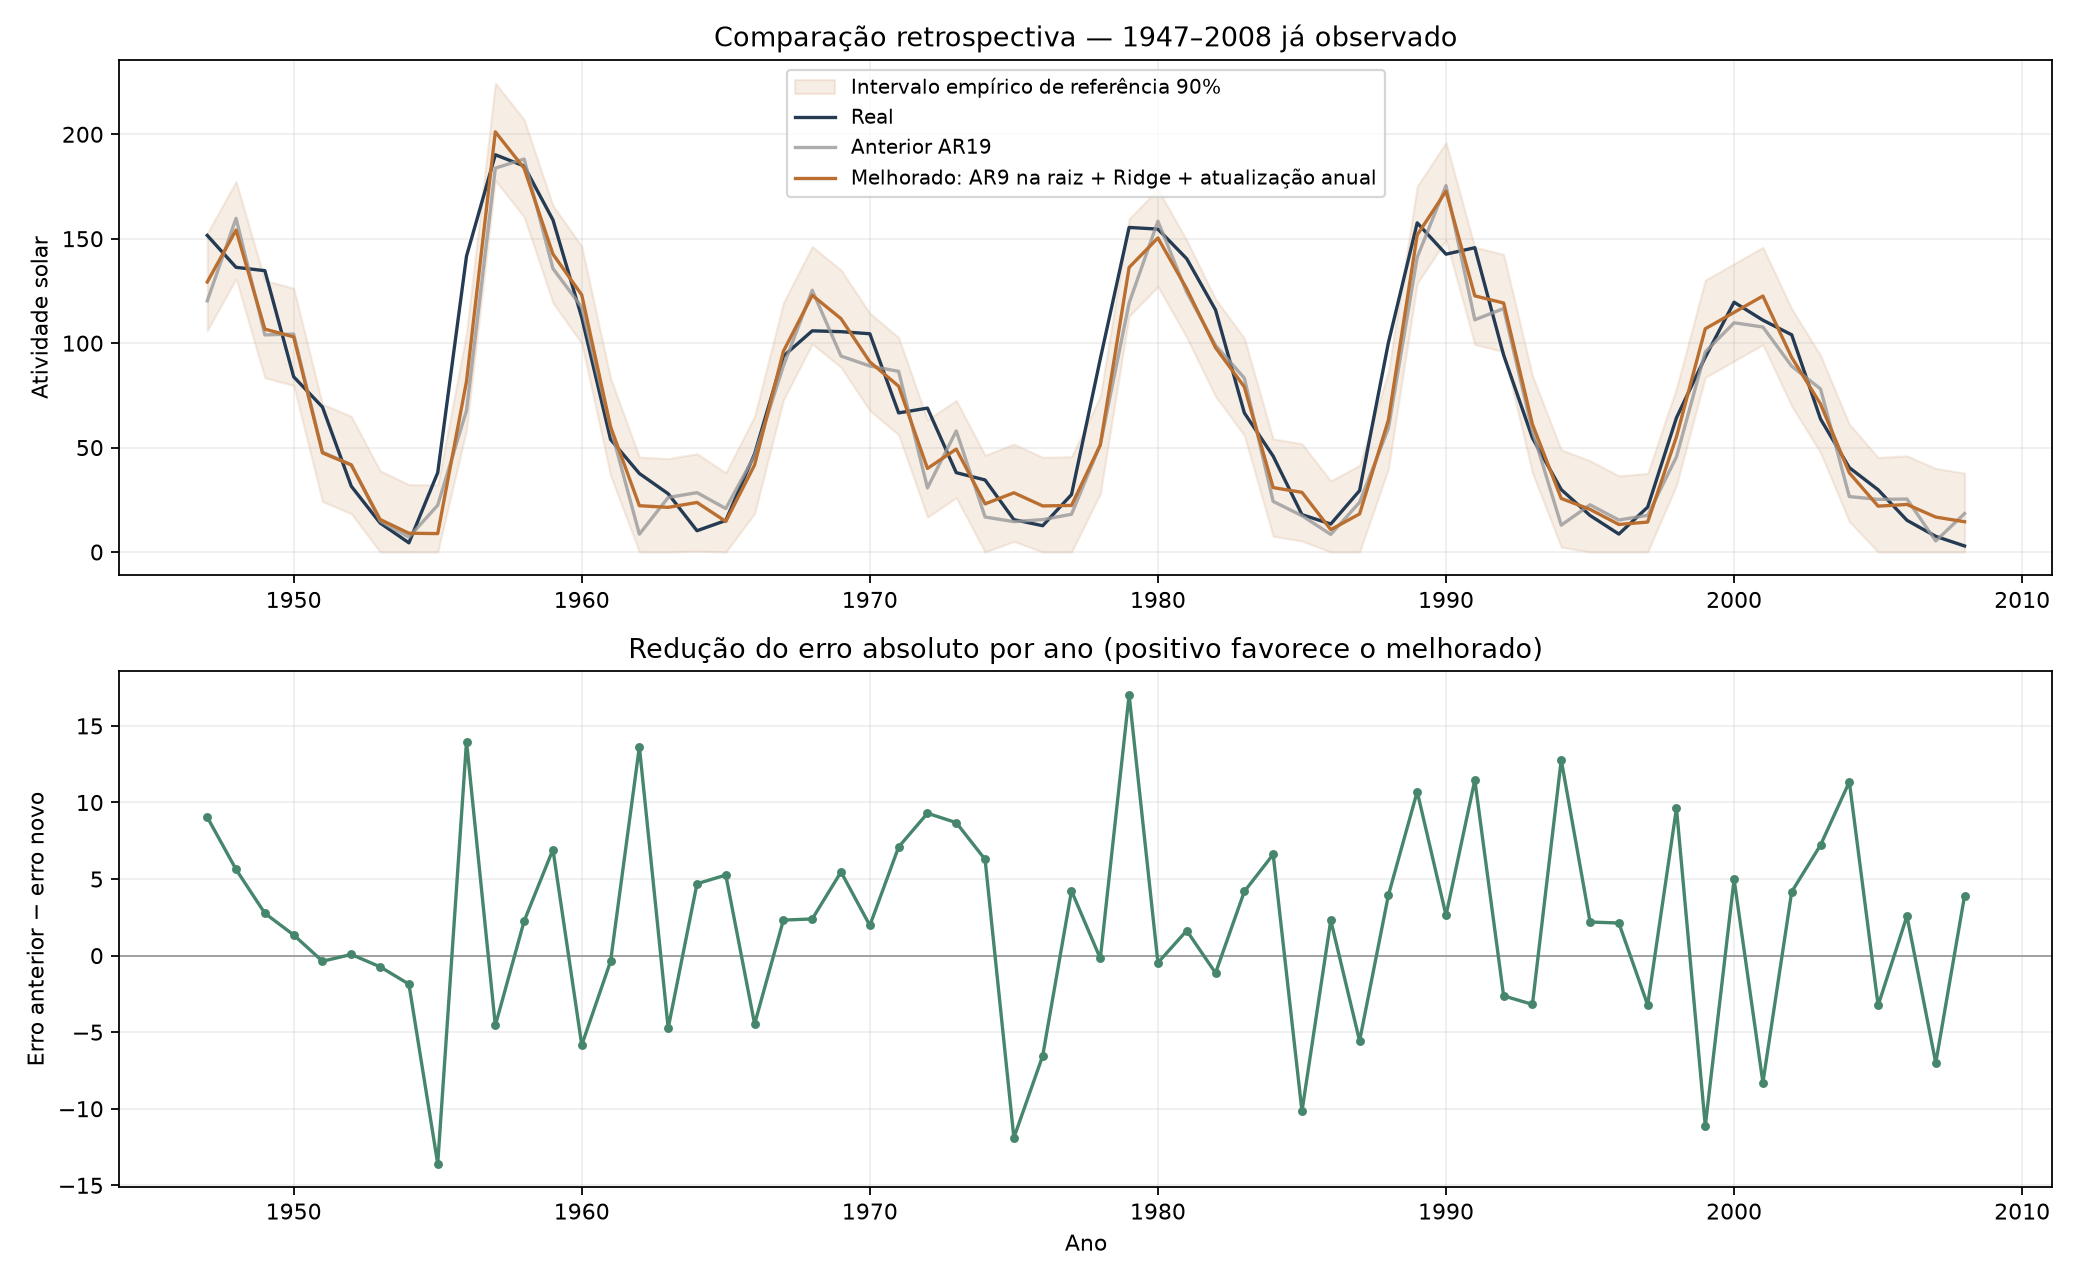

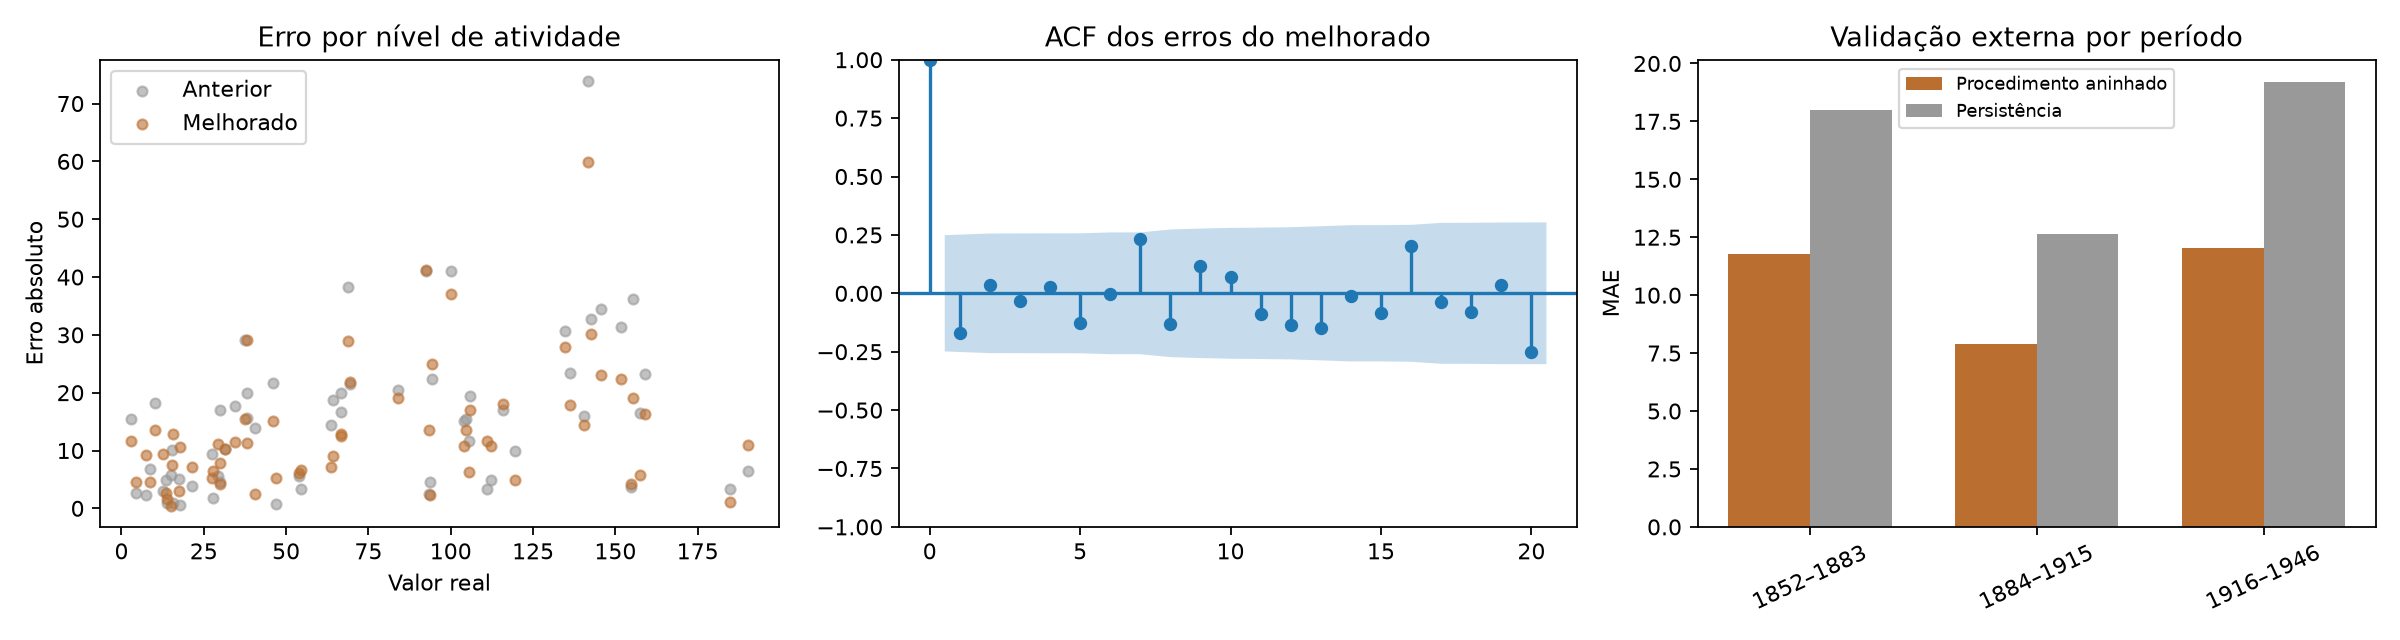

# Investigação do modelo de manchas solares

O modelo melhorou nesta comparação histórica, mas o período de 1947–2008 já foi visto. Não é um teste novo.

## O que foi investigado

- Dependência temporal e estacionariedade no desenvolvimento anterior a 1947.
- Erros por faixa de atividade, por período e autocorrelação dos erros de previsão.
- 126 configurações: 7 quantidades de defasagens, 3 transformações, 3 regularizações e 2 políticas de atualização.
- Quatro blocos cronológicos de validação e uma avaliação aninhada em que cada escolha usa só blocos anteriores.

## Modelo escolhido sem usar os resultados de 1947–2008 na busca

Configuração: {"transformacao": "raiz", "p": 9, "alpha": 1.0, "atualizacao": "expansivo"}.
É uma autorregressão linear na raiz quadrada da atividade, com Ridge para reduzir a instabilidade dos coeficientes. A volta à escala original eleva a previsão ao quadrado. Não foram adicionadas variáveis externas.
Os coeficientes são reajustados a cada ano, apenas com o passado. A ordem, a transformação e a regularização permanecem congeladas depois da seleção.
Todas as padronizações são ajustadas só no histórico disponível. Não há divisão aleatória nem previsão usando o próprio valor alvo.

## Comparação retrospectiva em 62 anos

| Modelo | MAE | RMSE | R² | MAPE | WAPE |
| --- | ---: | ---: | ---: | ---: | ---: |
| Anterior AR(19) | 15.28 | 20.24 | 0.853 | 36.27% | 20.71% |
| Melhorado | 13.28 | 16.99 | 0.896 | 34.14% | 18.01% |
| Persistência | 25.44 | 33.28 | 0.603 | 55.42% | 34.50% |

Redução frente ao anterior: MAE 13.1%; RMSE 16.1%.
Bootstrap pareado por blocos de 11 anos, 5.000 reamostragens: ganho médio de MAE 1.99; intervalo percentil de 95% [1.09, 2.92]. É uma análise descritiva, com poucos ciclos e sem ajuste pela seleção do modelo.

## Validação em períodos diferentes

O procedimento aninhado, avaliado em 95 anos externos, obteve MAE 10.55, contra 16.59 da persistência nos mesmos anos.
Cada bloco externo escolheu sua configuração pelos blocos anteriores. Isso avalia o procedimento de seleção; não equivale a avaliar a configuração final nos mesmos dados usados para escolhê-la.
O MAE do melhor candidato nos quatro blocos é uma medida usada na seleção e, por isso, otimista. O Excel mostra separadamente esse valor e a avaliação aninhada.

## Por que o percentual de erro permanece alto

| Modelo | Faixa real | Anos | MAE | MAPE |
| --- | --- | ---: | ---: | ---: |
| Anterior AR19 | Até 10 | 4 | 6.80 | 176.2% |
| Anterior AR19 | 10 a 50 | 23 | 9.60 | 38.1% |
| Anterior AR19 | 50 a 100 | 13 | 17.64 | 23.8% |
| Anterior AR19 | Acima de 100 | 22 | 21.36 | 16.2% |
| Melhorado | Até 10 | 4 | 7.50 | 170.2% |
| Melhorado | 10 a 50 | 23 | 8.88 | 37.8% |
| Melhorado | 50 a 100 | 13 | 15.86 | 20.8% |
| Melhorado | Acima de 100 | 22 | 17.42 | 13.4% |

A base tem mínimos próximos de zero. Neles, um erro absoluto pequeno pode virar um percentual enorme. A transformação busca estabilizar a amplitude, mas não elimina a dificuldade de antecipar picos e mínimos. Não foram excluídos mínimos para melhorar artificialmente os resultados.

## Diagnósticos e limites

No desenvolvimento, ADF apresentou p=0.0360; KPSS retornou p na borda superior da tabela (>=0,10). Os resultados não indicaram necessidade clara de diferenciação nesta especificação; não provam estacionariedade definitiva.
Ljung–Box dos erros de previsão, por defasagem, está no Excel. É descritivo: não houve correção por múltiplos testes, e rejeição isolada não demonstra um padrão fácil de prever.
O intervalo empírico calibrado em erros externos anteriores a 1947 cobriu 87.1% dos anos da comparação retrospectiva. A cobertura nominal de referência é 90%, sem garantia formal para esta série temporal.
Não aumentamos a busca depois de observar o desempenho final da configuração escolhida. Mesmo assim, toda esta investigação foi motivada por um teste já consultado: é necessário avaliar em anos ainda não utilizados ou em outra série independente antes de afirmar generalização.
Os dados disponíveis terminam em 2008. Não foram baixados anos adicionais nem misturadas versões do índice de atividade solar para criar um teste aparentemente novo.

## Executar

```bash
uv sync --locked
uv run --locked python prever_manchas.py
```

O script refaz busca, diagnósticos, comparação, planilha e gráficos. A versão anterior pode ser reproduzida com `uv run --locked python prever_manchas_original.py`.

## Referências

- Dataset: https://www.statsmodels.org/stable/datasets/generated/sunspots.html
- Autorregressões: https://www.statsmodels.org/stable/examples/notebooks/generated/autoregressions.html
- Diagnóstico Ljung–Box: https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html


Excel: /Users/ryanbernardo/Documents/Faculdade/MachineLearning/projeto_auto_regressao/resultados_manchas_solares/investigacao_manchas_solares.xlsx


In [3]:
excel=exportar(experimento,pasta)
graficos(experimento,pasta)
texto=relatorio(experimento,pasta)
display(Image(filename=str(excel.parent/'comparacao_modelos.png')))
display(Image(filename=str(excel.parent/'diagnostico_erros.png')))
display(Markdown(texto.read_text()))
print('Excel:',excel)
